Ryan Hughes Assignment 2 CNET 5050, Fall 2026
---

**Overall Instructions:** In Part 1 of this assignment, you will study the BA Model, Link selection model and the configuration
model. Submit your written solutions as a PDF prepared using LaTeX or Microsoft Word, along with the
source code used for your analysis. Ensure that your code is readable and appropriately commented. If
you use generative AI tools such as ChatGPT, identify the tasks for which they were used and include
the relevant prompts and generated outputs. In Part 2, you will develop your ability to critically read
and present network science research papers.

**Part 1**
In this question we will work with degree-controlled random graph null models.

Before beginning Part 1, review Advanced Topic 3.A, “Power Laws,” and Advanced Topic 3.B, “Plotting
Power Laws,” in the textbook: https://networksciencebook.com/chapter/4#advanced-a.
I. Barabasi–Albert Networks [20 points]
Write a program that generates a Barabasi–Albert network with N = $10^4$ nodes and attachment
parameter m = 4. 

Begin with a fully connected network of four nodes. Then add nodes one at a time, connecting each new node to m distinct existing nodes selected preferentially in proportion
to their degree. Implement the model yourself; do not use a built-in Barabasi–Albert network
generator. Include your source code with your submission. Record snapshots of the growing
network when it reaches N = $10^2$, $10^3$, and $10^4$ nodes.

(a) Visualize one realization of the BA network with N = $10^3$ nodes using a network visualization method of your choice.

(b) Generate NG = 100 independent graph realizations. For each realization, record the degree of every node at each snapshot size, N = 102, 103, and 104. For each snapshot size N, pool the degree observations across all realizations, giving NG ×N observations. Plot the log-binned empirical degree distribution P(k) on logarithmic axes for each network size and compare it with the theoretical asymptotic degree distribution of the BA model derived in class,

$$P(k) = \frac{2m(m + 1)}{k(k + 1)(k + 2)} ≈ 2m^2k^−3.$$

This expression applies for k ≥ m = 4. Clearly label the axes and distinguish the three network sizes in the legend. Refer to the lecture slides or the textbook on how to present the plots. What is the nature of the degree distribution in the BA model?

(c) Plot the complementary cumulative degree distributions, P(K ≥k), for the three network sizes together on the same axes. Clearly label the axes and legend.

(d) It is known that the average local clustering coefficient ⟨C⟩in the BA model scales as $$⟨C⟩∼(ln N)^2/N$$ (see Figure 5.19 and Advanced Topic 4.C). Generate NG = 100 independent graph realizations of size N = $10^4$. Measure the average clustering coefficient at several snapshots
as each network grows, average the measurements across the NG graphs, and plot the result as a function of network size N. Compare it with the theoretical scaling.

(e) Following Figure 5.6a, track the degree over time of one node from the initial four-node network and of nodes added at times t = 10, 100, 1000, and 5000. Define t as the number of node additions after the initial network. Plot the degree of each tracked node, averaged over
NG = 100 graphs, as a function of t from its introduction through the end of the simulation. Compare the results with the theoretical scaling derived in class,

$ k_i(t) = m\sqrt{\frac{t}{ti}} $ 


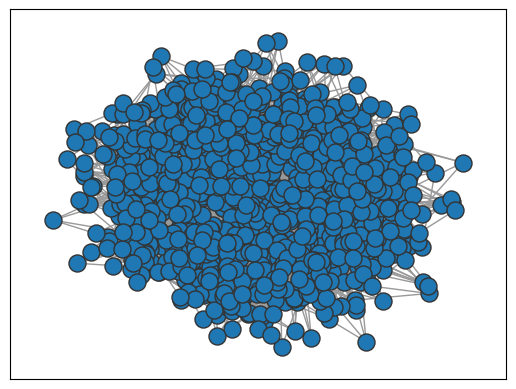

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from itertools import combinations
import logging
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import binom
from scipy.special import comb

def network_growth_model(N,alpha=4):
    """
    Generates a Network Growth Model using preferential attachment.

    Parameters
    ----------
    N : int
        The number of vertices of the graph to generate.
    
    alpha : float
        The average number of edges to make for each node added to the graph

    Returns
    -------
    G : networkx.Graph
        A graph generated from the given number of nodes and connections per node added (alpha). 

    Snapshot_10 : networkx.Graph
        A snapshot of 'G' when N=10

    Snapshot_10_2 : networkx.Graph
        A snapshot of 'G' when N=10^2

    Snapshot_10_3 : networkx.Graph
        A snapshot of 'G' when N=10^3

    Snapshot_10_4 : networkx.Graph
        A snapshot of 'G' when N=10^4
       

    Time Complexity
    ---------------
    The time complexity is dominated by O(N**2), where N is the number of nodes we want to add to the graph,
    each with an 'alpha' number of connections. Where alpha is bounded by N the number of new nodes we 
    want to provide alpha connections for.

    Example
    -------
    >>> N = 100
    >>> alpha = 3
    >>> G = network_growth_model(N,alpha)
    """
    #Instantiate G as a fully connected graph of 4 nodes
    G = nx.complete_graph(4)

    #Initialize snapshots
    Snapshot_10=0
    Snapshot_10_2=0
    Snapshot_10_3=0
    Snapshot_10_4=0
    #Concept:
    #For every new node we want to add,
        #First if there are no connections then just add connect to what we initialized with
    #Find the probabilities of connecting to all the existing nodes currently
    #Pick 'alpha' nodes at random based on said probabilities
    #Add a new node and connect it to each of the list of 'alpha' nodes
    #Repeat for all 'N' new nodes

    while N>0:#While we still have nodes to add...
        nodes = list(G.nodes())#Get the current list of nodes...
        degs = np.array([(G.degree[n]) for n in nodes], dtype=float)#And, get their probabilities.
        
        #Translating alpha into an N value so that on average 'alpha' connections are made even if this is a float
        m = int(np.floor(alpha)) + (np.random.rand() < alpha - np.floor(alpha))
        
        #Edge Case: If this is the first run where we start with a Graph with no connections
        if degs.sum() == 0:
            chosen = nodes #then just instantiate to the few nodes we initialized with                     
        else:
            #Otherwise, pick 'm' connections to make **without replacement**,
            #  by the probability calculated from their degree(s)
            chosen = np.random.choice(nodes, size=m, replace=False, p=degs / degs.sum())
        #Add the new node as the next id number
        new_id = len(nodes)
        #And connect it to 'alpha' chosen nodes
        for node_i in chosen:
            G.add_edge(int(node_i), new_id)
        #Update N to reflect that we processed 1 new node!
        N-=1
        #Create a single snapshot per size once each threshold is reached:
        if(G.number_of_nodes()>=10 and Snapshot_10==0):
            Snapshot_10 = G.copy()
        if(G.number_of_nodes()>=10**2 and Snapshot_10_2==0):
            Snapshot_10_2 = G.copy()
        if(G.number_of_nodes()>=10**3 and Snapshot_10_3==0):
            Snapshot_10_3 = G.copy()
        if(G.number_of_nodes()>=10**4 and Snapshot_10_4==0):
            Snapshot_10_4 = G.copy()

    return G,Snapshot_10,Snapshot_10_2,Snapshot_10_3,Snapshot_10_4

G,Snapshot_10,Snapshot_10_2,Snapshot_10_3,Snapshot_10_4 = network_growth_model(10**4)

#(a)
pos = nx.spring_layout(Snapshot_10_3)

fig_a = plt.plot()
nx.draw_networkx(Snapshot_10_3, pos, node_size=150, edgecolors='.2', with_labels=False, font_size='x-small', edge_color='.6')


In [3]:
#(b) Getting the Degree Distributions per Snapshot
degs_10_2=[]
degs_10_3=[]
degs_10_4=[]
for i in range(1,101):
    G,Snapshot_10,Snapshot_10_2,Snapshot_10_3,Snapshot_10_4 = network_growth_model(10**4)
    degs_10_2.append(list(dict(Snapshot_10_2.degree()).values()))
    degs_10_3.append(list(dict(Snapshot_10_3.degree()).values()))
    degs_10_4.append(list(dict(Snapshot_10_4.degree()).values()))


[[20, 29, 14, 28, 33, 30, 28, 11, 14, 16, 15, 18, 17, 7, 19, 9, 15, 13, 10, 11, 10, 6, 11, 8, 4, 9, 4, 8, 9, 5, 5, 4, 11, 12, 4, 8, 6, 5, 7, 5, 5, 5, 5, 4, 5, 6, 6, 6, 7, 5, 5, 8, 5, 8, 4, 5, 5, 4, 4, 4, 6, 4, 4, 4, 5, 4, 4, 4, 4, 6, 8, 4, 4, 4, 5, 5, 4, 5, 5, 4, 4, 4, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 4, 4, 5, 4], [25, 37, 40, 37, 15, 25, 20, 7, 15, 11, 9, 18, 17, 13, 14, 8, 7, 7, 10, 17, 7, 8, 10, 7, 6, 10, 6, 7, 7, 5, 5, 7, 6, 8, 6, 8, 6, 6, 4, 7, 6, 5, 7, 5, 8, 7, 6, 8, 6, 4, 6, 7, 5, 4, 4, 4, 5, 4, 5, 5, 5, 7, 5, 5, 5, 4, 5, 5, 6, 4, 5, 5, 4, 4, 4, 5, 4, 5, 4, 4, 5, 4, 6, 4, 5, 4, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4], [18, 20, 16, 29, 29, 9, 21, 21, 13, 19, 13, 15, 11, 24, 7, 8, 7, 19, 15, 11, 13, 6, 12, 9, 7, 4, 8, 14, 6, 5, 9, 10, 9, 8, 7, 8, 9, 5, 6, 5, 4, 10, 4, 4, 6, 5, 6, 6, 7, 5, 6, 6, 4, 5, 5, 6, 5, 7, 5, 5, 7, 5, 5, 5, 6, 6, 4, 4, 6, 5, 6, 5, 5, 4, 4, 5, 4, 5, 6, 5, 4, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4], [25, 17, 28, 36, 22, 15, 12, 20, 

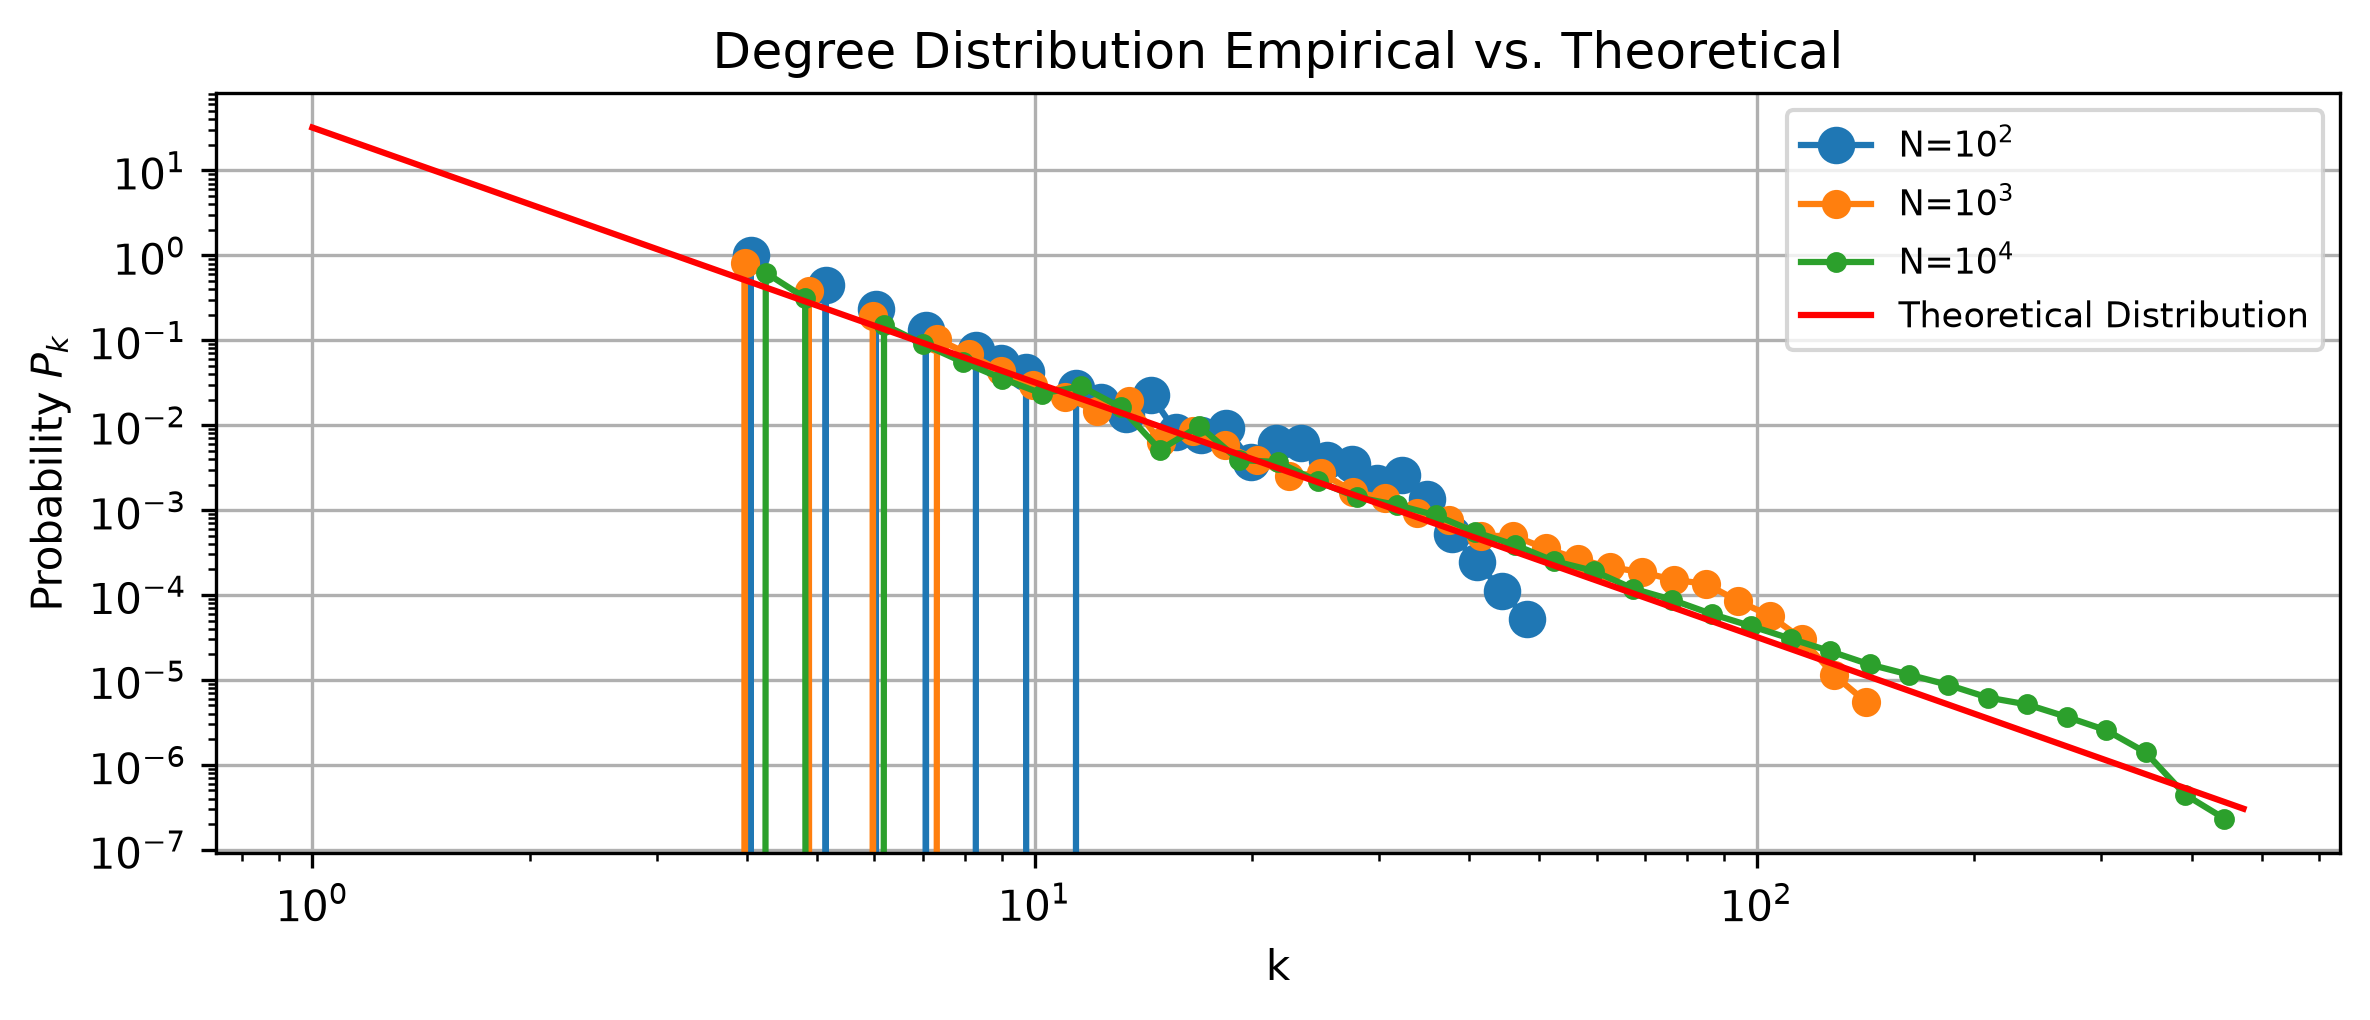

In [4]:
m=4
k=list(range(1,np.max(list(degs_10_4))))
print(degs_10_2)
theoretical = [2*(m**2)*(k_i**-3) for k_i in k]

#---Plotting the Degree Distribution 'k'
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=300,sharey=True,sharex=True)#Note: fig is the plot container, while ax (i.e., the 'axes') is the plot itself
bins = np.geomspace(1,np.max(list(degs_10_2)))

counts1, bin_edges = np.histogram(degs_10_2, bins=bins, density=True)
#NOTE: list[:-1] is every item in the list up to the last (not including last)
#and bin_edges[1:] is every item starting from 1 (i.e., not the 0th or first index)
#sqrt() is the center of a log-bin. As oppossed to the standard mean()
bin_centers_10_2 = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers_10_2, counts1, marker='o', ms = 8, label="N=$10^2$")

bins = np.geomspace(1,np.max(list(degs_10_3)))
counts2, bin_edges = np.histogram(degs_10_3, bins=bins, density=True)
bin_centers_10_3 = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers_10_3, counts2, marker='o', ms = 6,label="N=$10^3$")

bins = np.geomspace(1,np.max(list(degs_10_4)))
counts3, bin_edges = np.histogram(degs_10_4, bins=bins, density=True)
bin_centers_10_4 = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers_10_4, counts3, marker='o', ms = 4,label="N=$10^4$")


ax.loglog()
ax.plot(k,theoretical, color = 'r',ms = 2,label="Theoretical Distribution") #Plotting the Theoretical

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("Degree Distribution Empirical vs. Theoretical")
ax.set_xlabel("k")
ax.set_ylabel("Probability $P_k$")
ax.grid(True)

plt.tight_layout()
plt.show()

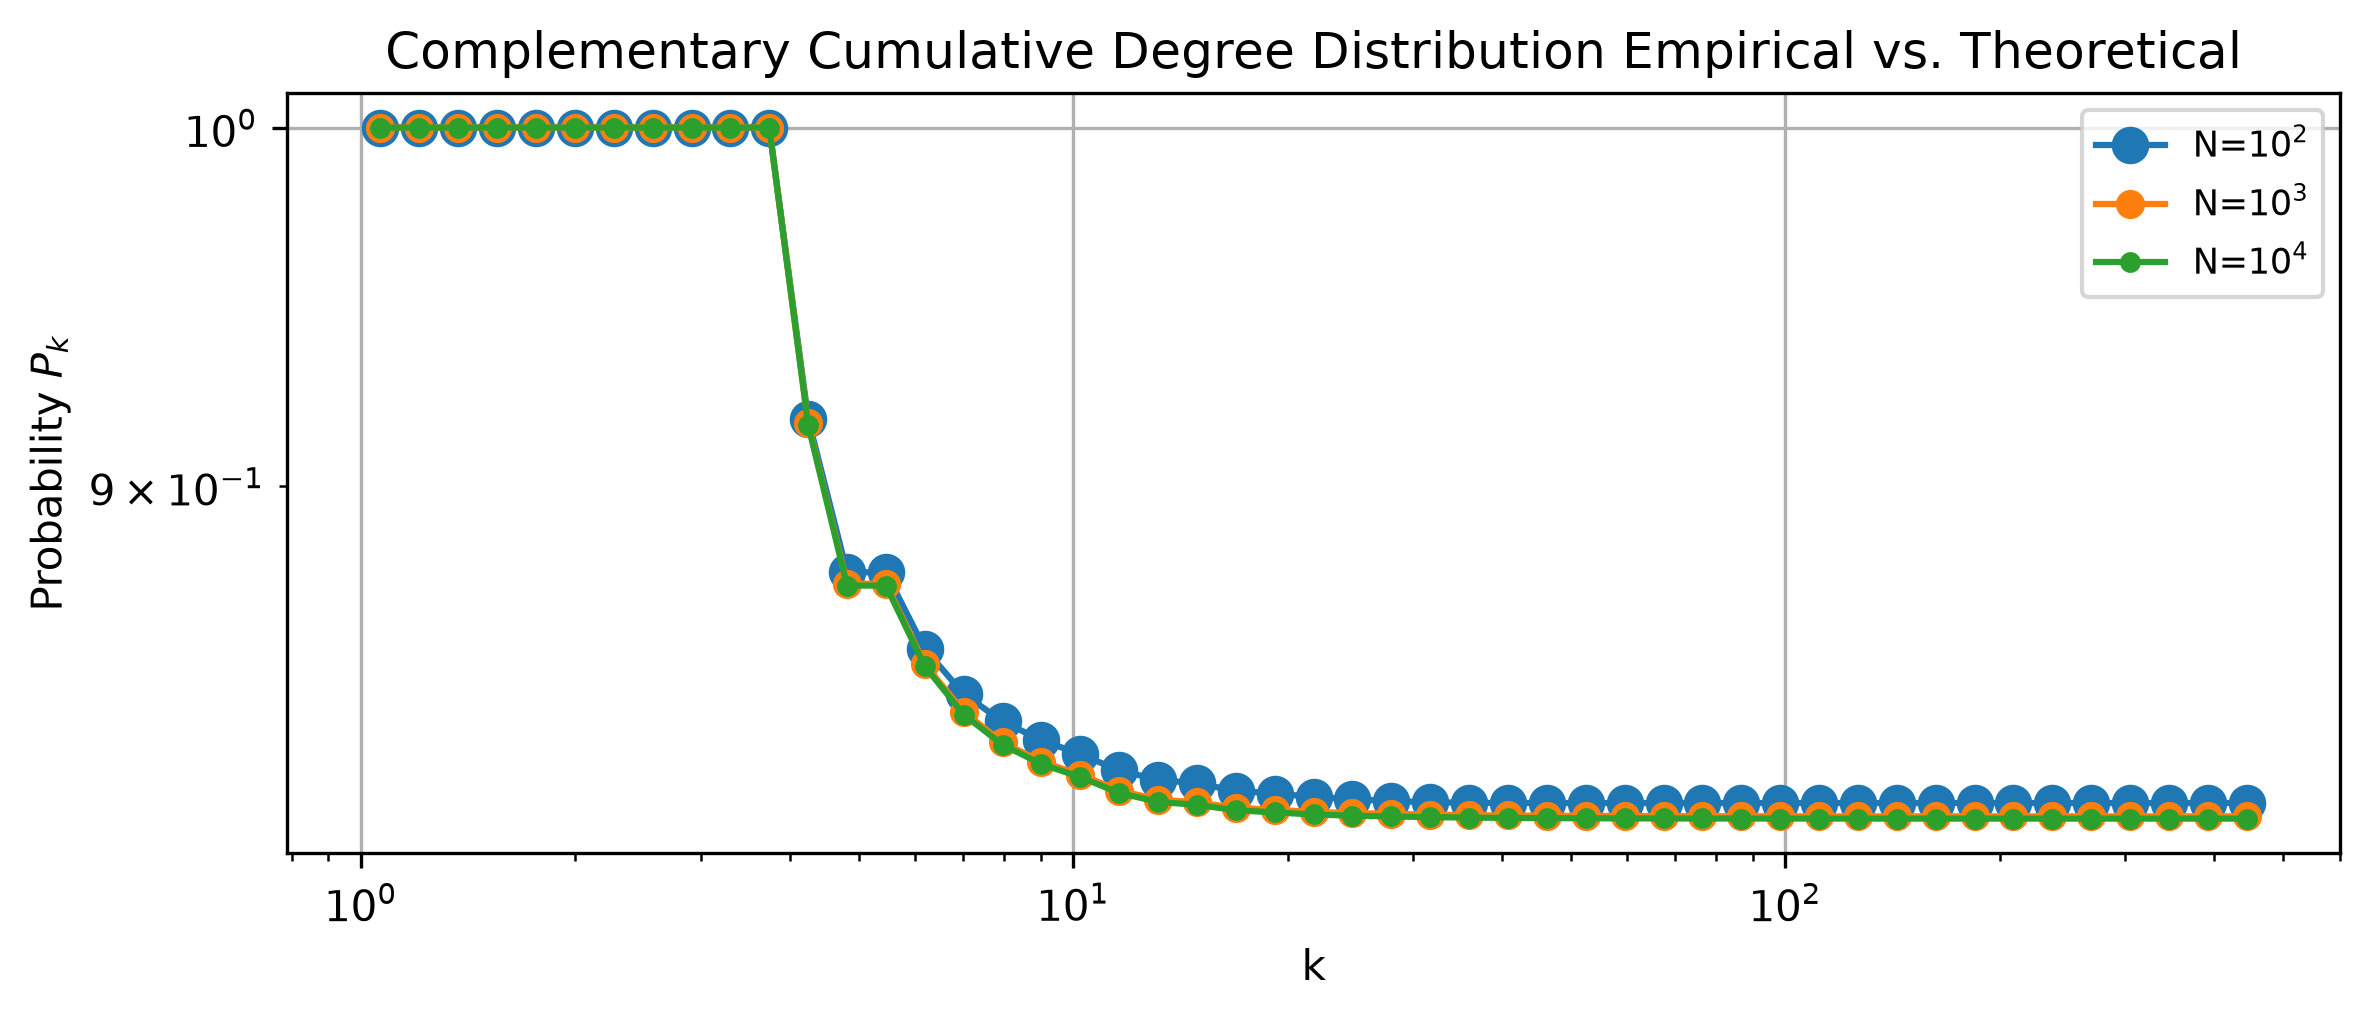

In [5]:
#(c)

#---Plotting the Complementary Cumulative Degree Distribution 'k'
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=300,sharey=True,sharex=True)#Note: fig is the plot container, while ax (i.e., the 'axes') is the plot itself
bins = np.geomspace(1,np.max(list(degs_10_4)))

counts, bin_edges = np.histogram(degs_10_2, bins=bins, density=True)
bin_centers_10_2 = np.sqrt(bin_edges[:-1] * bin_edges[1:])
dx = bin_edges[1] - bin_edges[0]
ccdd = 1-(np.cumsum(counts)*dx)
ax.loglog(bin_centers_10_2, ccdd, marker='o', ms = 8,label="N=$10^2$")

counts, bin_edges = np.histogram(degs_10_3, bins=bins, density=True)
bin_centers_10_3 = np.sqrt(bin_edges[:-1] * bin_edges[1:])
dx = bin_edges[1] - bin_edges[0]
ccdd = 1-(np.cumsum(counts)*dx)
ax.loglog(bin_centers_10_3, ccdd, marker='o', ms = 6,label="N=$10^3$")

counts, bin_edges = np.histogram(degs_10_4, bins=bins, density=True)
bin_centers_10_4 = np.sqrt(bin_edges[:-1] * bin_edges[1:])
dx = bin_edges[1] - bin_edges[0]
ccdd = 1-(np.cumsum(counts)*dx)
ax.loglog(bin_centers_10_4, ccdd, marker='o', ms = 4,label="N=$10^4$")

ax.loglog()

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("Complementary Cumulative Degree Distribution Empirical vs. Theoretical")
ax.set_xlabel("k")
ax.set_ylabel("Probability $P_k$")
ax.grid(True)

plt.tight_layout()
plt.show()

In [7]:
#Getting the Clustering per Snapshot
cc_10_2=[]
cc_10_3=[]
cc_10_4=[]
for i in range(1,101):
    G,Snapshot_10,Snapshot_10_2,Snapshot_10_3,Snapshot_10_4 = network_growth_model(10**4)
    cc_10_2.append(nx.average_clustering(Snapshot_10_2))
    cc_10_3.append(nx.average_clustering(Snapshot_10_3))
    cc_10_4.append(nx.average_clustering(Snapshot_10_4))

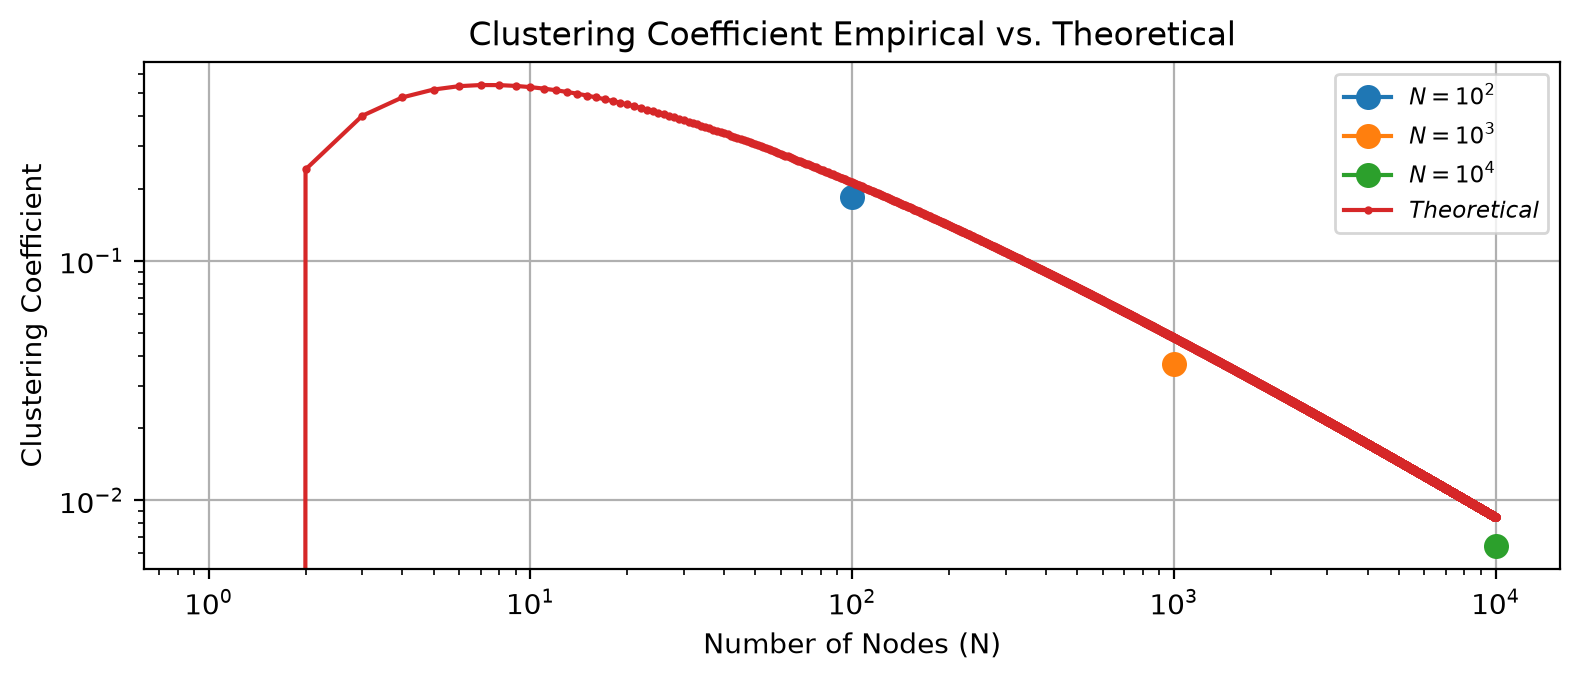

In [13]:
#(d)

#---Plotting the Local Clustering Coefficient Distribution 'CC'
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=200,sharex=True,sharey=True)

#Since there are cases where the minimum CC can be 0, 
# I'm starting the plot with the second-most minimum

#Gathering 2nd most mins
cc_10_2=np.asarray(cc_10_2)
cc_10_2_min2= np.amin(cc_10_2[cc_10_2 != np.amin(cc_10_2)])
cc_10_3=np.asarray(cc_10_3)
cc_10_3_min2= np.amin(cc_10_3[cc_10_3 != np.amin(cc_10_3)])
cc_10_4=np.asarray(cc_10_4)
cc_10_4_min2= np.amin(cc_10_4[cc_10_4 != np.amin(cc_10_4)])

N = range(1,(10**4) +1)
cc_t= [(np.log(N_i)**2)/(N_i) for N_i in N]
cc_t=np.asarray(cc_t)
cc_t_min2= np.amin(cc_t[cc_t != np.amin(cc_t)])

cc_bins2 = np.geomspace(cc_10_2_min2,np.max(cc_10_2))
cc_bins3 = np.geomspace(cc_10_3_min2,np.max(cc_10_3))
cc_bins4 = np.geomspace(cc_10_4_min2,np.max(cc_10_4))
cc_bins5 = np.geomspace(cc_t_min2,np.max(cc_t))

counts, bin_edges = np.histogram(cc_10_2, bins=cc_bins2, density=True)

bin_centers_10_2 = np.sqrt(bin_edges[:-1] * bin_edges[1:])
#ax.loglog(bin_centers_10_2, counts, marker='o', ms=8, label="$N=10^2$")
ax.loglog(10**2, np.mean(cc_10_2), marker='o', ms=8, label="$N=10^2$")

counts, bin_edges = np.histogram(cc_10_3, bins=cc_bins3, density=True)
bin_centers_10_3 = np.sqrt(bin_edges[:-1] * bin_edges[1:])
#ax.loglog(bin_centers_10_3, counts, marker='o',ms=6,label="$N=10^3$")
ax.loglog(10**3, np.mean(cc_10_3), marker='o', ms=8, label="$N=10^3$")

counts, bin_edges = np.histogram(cc_10_4, bins=cc_bins4, density=True)
bin_centers_10_4 = np.sqrt(bin_edges[:-1] * bin_edges[1:])
#ax.loglog(bin_centers_10_4, counts, marker='o',ms=4,label="$N=10^4$")
ax.loglog(10**4, np.mean(cc_10_4), marker='o', ms=8, label="$N=10^4$")

counts, bin_edges = np.histogram(cc_t, bins=cc_bins5, density=True)
bin_centers_t = np.sqrt(bin_edges[:-1] * bin_edges[1:])
#ax.loglog(bin_centers_t, counts, marker='o',ms=2,label="Theoretical Average")
ax.loglog(N, cc_t, marker='o', ms=2, label="$Theoretical$")

#ax.plot(N,cc_t,color = 'b',label="Theoretical Average")

ax.loglog()

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("Clustering Coefficient Empirical vs. Theoretical")
ax.set_xlabel("Number of Nodes (N)")
ax.set_ylabel("Clustering Coefficient")
#ax.set_ylabel("Probability $P_{CC}$")
ax.grid(True)

plt.tight_layout()
plt.show()

In [15]:
#(e)
tracked_10=[]
tracked_10_2=[]
tracked_10_3=[]
tracked_G=[]
for i in range(1,101):#Tracking the first node
    G,Snapshot_10,Snapshot_10_2,Snapshot_10_3,Snapshot_10_4 = network_growth_model(5000)
    tracked_10.append(list(dict(Snapshot_10.degree()).values())[0])
    tracked_10_2.append(list(dict(Snapshot_10_2.degree()).values())[0])
    tracked_10_3.append(list(dict(Snapshot_10_3.degree()).values())[0])
    tracked_G.append(list(dict(G.degree()).values())[0])


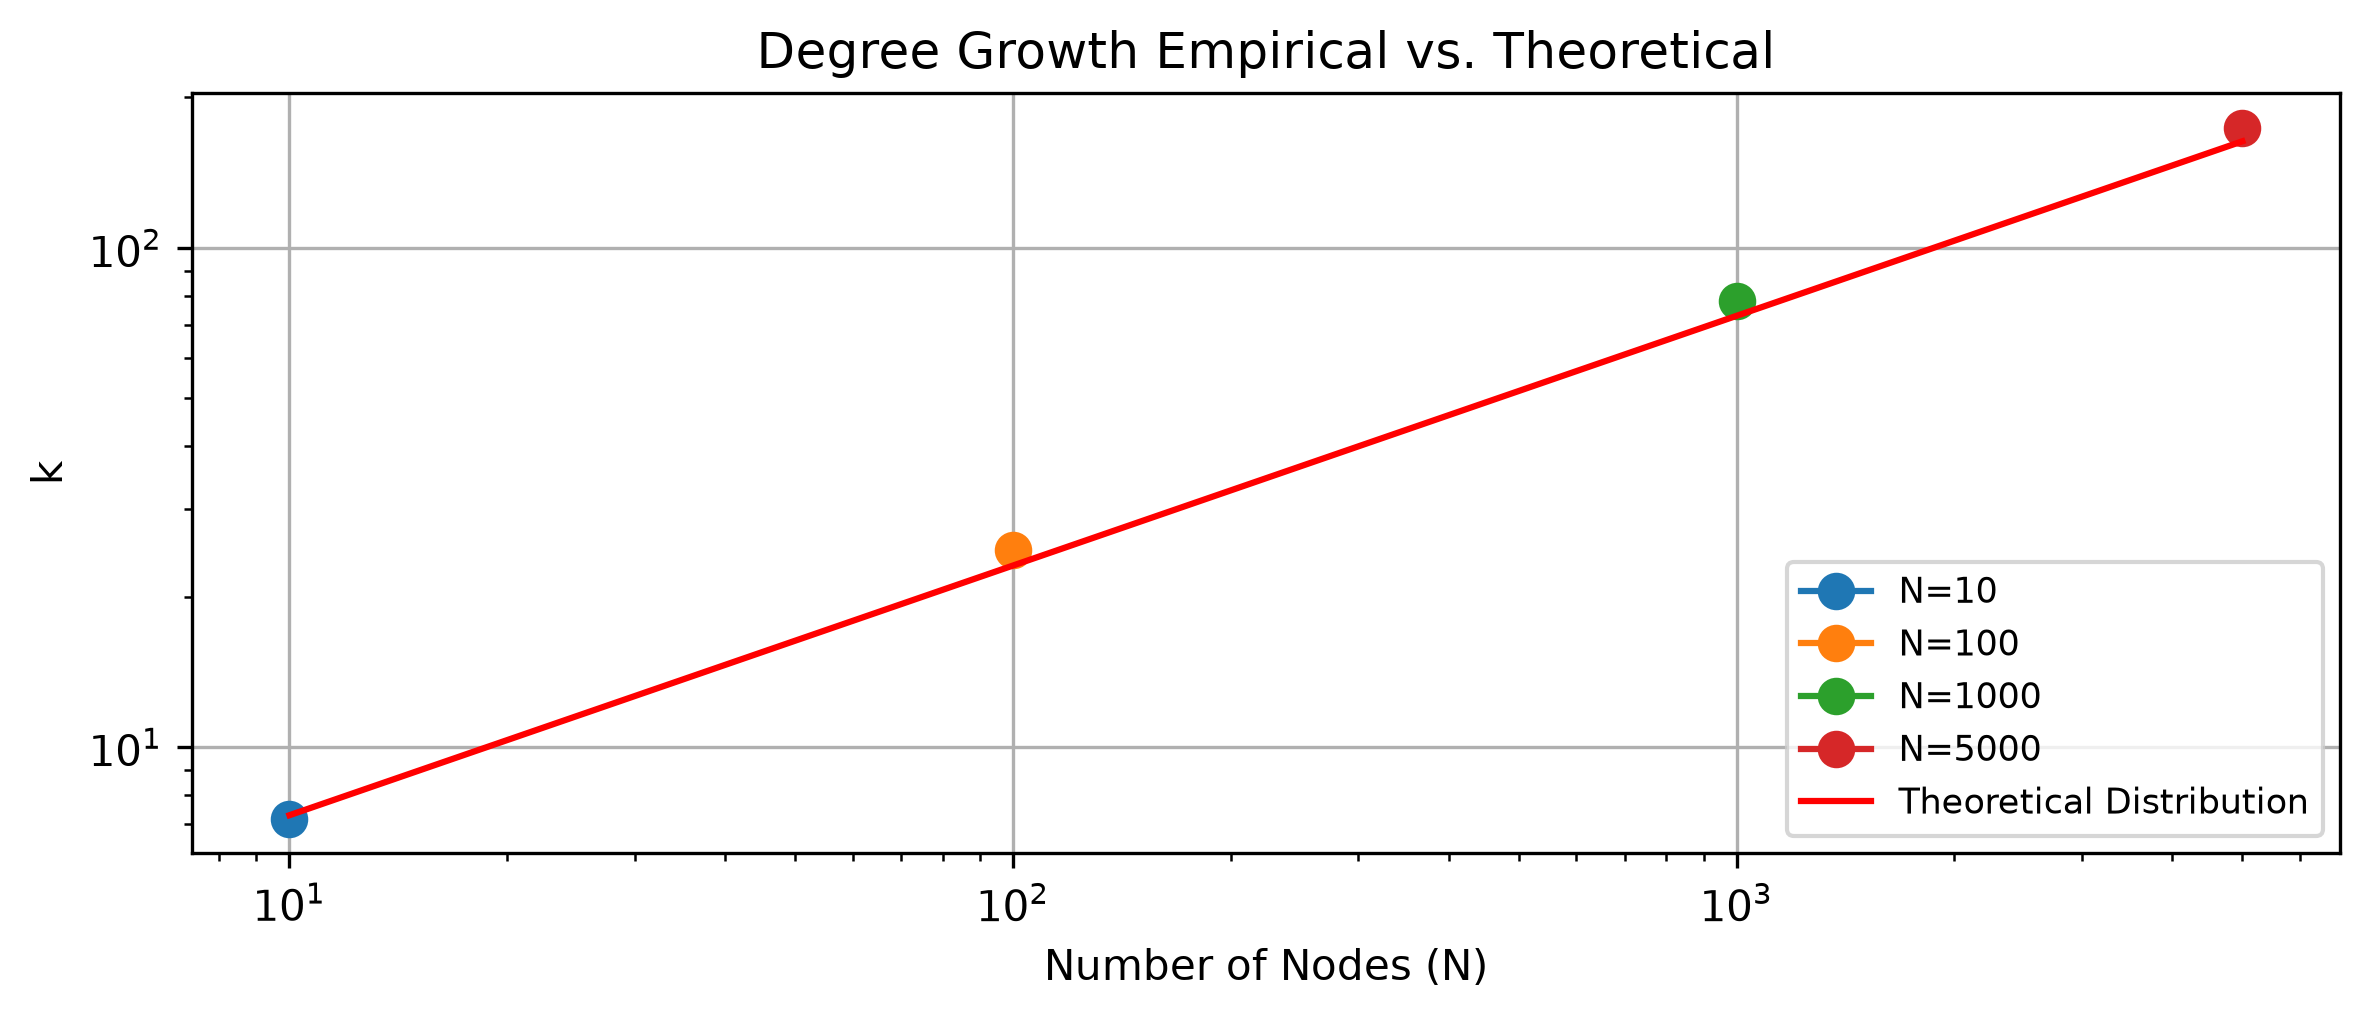

In [23]:
m=4
t=[10,100,1000,5000]
t_init = 3 #For a N=4 complete graph, t_i=3
theoretical = [m*np.sqrt(t_i/t_init) for t_i in t]

#---Plotting the Degree Distribution 'k'
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=300,sharey=True,sharex=True)#Note: fig is the plot container, while ax (i.e., the 'axes') is the plot itself
bins = np.geomspace(1,np.max((tracked_10)))

counts, bin_edges = np.histogram(tracked_10, bins=bins, density=True)
bin_centers_10 = np.sqrt(bin_edges[:-1] * bin_edges[1:])
#ax.loglog(bin_centers_10, counts, marker='o', ms=8, label="N=10")
ax.loglog(10, np.mean(tracked_10), marker='o', ms=8, label="N=10")

bins = np.geomspace(1,np.max((tracked_10_2)))
counts, bin_edges = np.histogram(tracked_10_2, bins=bins, density=True)
bin_centers_10_2 = np.sqrt(bin_edges[:-1] * bin_edges[1:])
#ax.loglog(bin_centers_10_2, counts, marker='o',ms=6,label="N=100")
ax.loglog(10**2, np.mean(tracked_10_2), marker='o', ms=8, label="N=100")

bins = np.geomspace(1,np.max((tracked_10_3)))
counts, bin_edges = np.histogram(tracked_10_3, bins=bins, density=True)
bin_centers_10_3 = np.sqrt(bin_edges[:-1] * bin_edges[1:])
#ax.loglog(bin_centers_10_3, counts, marker='o',ms=4,label="N=1000")
ax.loglog(10**3, np.mean(tracked_10_3), marker='o', ms=8, label="N=1000")

bins = np.geomspace(1,np.max((tracked_G)))
counts, bin_edges = np.histogram(tracked_G, bins=bins, density=True)
bin_centers_G = np.sqrt(bin_edges[:-1] * bin_edges[1:])
#ax.loglog(bin_centers_G, counts, marker='o',ms=2,label="N=5000")
ax.loglog(5e3, np.mean(tracked_G), marker='o', ms=8, label="N=5000")


#ax.hist(tracked_10,bins=bins,label="N=10",density=True)#Plotting the configuration model graph empirical data
#ax.hist(tracked_10_2,bins=bins,label="N=10^2",density=True)#Plotting the Chung Lu model graph empirical data
#ax.hist(tracked_10_3,bins=bins,label="N=10^3",density=True)#Plotting the Chung Lu model graph empirical data
#ax.hist(tracked_G,bins=bins,label="N=5e3",density=True)#Plotting the Chung Lu model graph empirical data
ax.loglog(t,theoretical, color = 'r',label="Theoretical Distribution") #Plotting the Theoretical

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="lower right",fontsize="small")
ax.set_title("Degree Growth Empirical vs. Theoretical")
ax.set_ylabel("k")
ax.set_xlabel("Number of Nodes (N)")
#ax.set_ylabel("Probability P_k")
ax.grid(True)

plt.tight_layout()
plt.show()


II. The Friendship Paradox [30 points]
The link selection model (see Chapter 5) is a simple local mechanism that generates a scale-free network without an explicit preferential-attachment rule. The model is defined as follows:

* Growth: At each time step, add a new node to the network.
* Link selection: Select a link uniformly at random, then connect the new node to one of its endpoints, chosen uniformly at random.

(a) Write a program that generates a network from the link selection model described above. Initialize the network with two nodes connected by an edge.

(b) Generate NG = 100 independent graph realizations of size N = 104. Pool the degreeobservations across all realizations, giving NG×N observations. Plot the log-binned empirical degree distribution P(k) on logarithmic axes for this network size. Compare the empirical
distribution with Eq. (1) using m = 1. Explain how the link selection model creates an effective preferential-attachment mechanism by giving the form of $ \Pi_i  = \Pi_{ki}$, the probability that the incoming node connects to an existing node i of degree ki.

(c) The configuration model is a paradigmatic “equilibrium” random network model and is often used as a null model to randomize connections while preserving a specified degree sequence and isolate the effects of degree heterogeneity. Let P(k) denote the degree distribution, where
k is an integer. Show that the probability that a node at the end of a uniformly selected edge has degree k is Q(k) = kP(k)/⟨k⟩, where ⟨k⟩= ∑
k kP(k) is the average degree.

(d) Using the form of Q(k), derive the expected degree ⟨kneigh⟩of a neighbor in the configuration
model in terms of the first and second moments of P(k).

(e) Let P(k) = Ck−γ for integer degrees kmin ≤k ≤kmax. Determine the normalization constant
C and the first and second moments of this distribution in terms of γ, kmin, and kmax.

(f) For a network with N = 104, γ = 2.3, kmin = 1, and kmax = 1000, calculate the mean degree of
a neighbor ⟨kneigh⟩and the network’s mean degree ⟨k⟩. Use the discrete truncated power-law
distribution specified above, and compare the two values.

(g) Explain the friendship paradox in light of your result: why do the friends of a randomly
selected node have a higher mean degree than the nodes themselves?

In [74]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from itertools import combinations
import logging
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import binom
from scipy.special import comb
import random

def link_selection_model(N):
    """
    Generates a link selection model without using preferential attachment.

    Parameters
    ----------
    N : int
        The number of vertices of the graph to generate.
    
    Returns
    -------
    G : networkx.Graph
        A graph generated from the given number of nodes and connections per node added (alpha). 
       

    Time Complexity
    ---------------
    The time complexity is  O(N), where N is the number of nodes we want to add to the graph,
    each with an 1 connection. 

    Example
    -------
    >>> N = 10**4
    >>> G = link_selection_model(N)
    """
    #Instantiate G as a fully connected graph of 2 nodes
    G = nx.complete_graph(2)

    #Concept:
    #At each time step, add a new node to the network.
    #Link Selection: select an edge uniformly at random, and then connect the new node to one of this edge's endpoints, also chosen uniformly at random

    #We expect edges are selected randomly from the set of all edges
    #And the nodes to connect to at the ends of said edges are
    #effectively, a coin-flip connection

    #Steps:
    #First get the set of all edges, and sample 1 random edge
    #Obtain this edge's nodes.
    #Randomly sample between the two nodes (e.g., random.rand <.50)
    #Then add our new node to our selected node
    while N>0:#While we still have nodes to add...
        edges_set = list(G.edges())#Get the current list of edges...
        #Add the new node as the next id number
        new_id = len(G.nodes())
        #Sample for a random edge
        node_i,node_j = random.sample((edges_set),k=1)[0]
        if(np.random.rand()<.50):#Sample for a random node within said edge
            G.add_edge(int(new_id),node_i)
        else:
            G.add_edge(int(new_id),node_j)
        
        #Update N to reflect that we processed 1 new node!
        N-=1

    return G

G = link_selection_model(10**4)


In [75]:
#(b) Getting the Degree Distributions per realization
degs=[]
for i in range(1,101):
    G = link_selection_model(10**4)
    degs.append(list(dict(G.degree()).values()))

[[49, 170, 22, 73, 177, 6, 31, 32, 77, 73, 17, 18, 2, 3, 96, 6, 35, 7, 15, 12, 53, 13, 2, 49, 2, 35, 6, 39, 21, 15, 16, 8, 15, 9, 24, 21, 13, 15, 5, 2, 10, 43, 7, 3, 26, 4, 12, 7, 1, 5, 2, 22, 22, 7, 17, 5, 47, 7, 4, 15, 27, 4, 1, 58, 1, 4, 7, 2, 1, 2, 13, 1, 34, 13, 20, 8, 46, 7, 2, 10, 15, 1, 5, 1, 9, 10, 17, 6, 25, 1, 11, 5, 11, 14, 6, 5, 54, 9, 12, 13, 18, 3, 1, 2, 19, 4, 6, 1, 19, 9, 7, 8, 4, 4, 9, 5, 9, 26, 3, 27, 2, 3, 11, 2, 25, 3, 14, 7, 5, 6, 11, 17, 4, 21, 22, 6, 3, 12, 18, 2, 8, 2, 14, 2, 17, 2, 4, 22, 3, 28, 3, 18, 2, 6, 2, 6, 8, 1, 12, 2, 5, 2, 3, 2, 9, 1, 6, 4, 2, 2, 2, 15, 3, 2, 1, 1, 7, 2, 7, 3, 5, 5, 1, 24, 1, 14, 7, 4, 11, 5, 2, 24, 1, 12, 8, 6, 1, 3, 1, 5, 13, 2, 4, 25, 3, 6, 37, 4, 1, 5, 4, 5, 3, 9, 4, 4, 8, 1, 15, 5, 3, 8, 1, 10, 9, 24, 11, 3, 6, 7, 5, 17, 1, 4, 3, 6, 2, 8, 2, 2, 1, 13, 2, 5, 5, 1, 3, 1, 1, 3, 7, 7, 18, 5, 3, 8, 7, 4, 12, 3, 4, 2, 2, 2, 9, 6, 5, 1, 10, 1, 4, 4, 3, 2, 1, 14, 3, 1, 3, 5, 1, 9, 12, 1, 14, 9, 6, 1, 1, 2, 4, 3, 13, 1, 11, 2, 5, 4, 1, 6

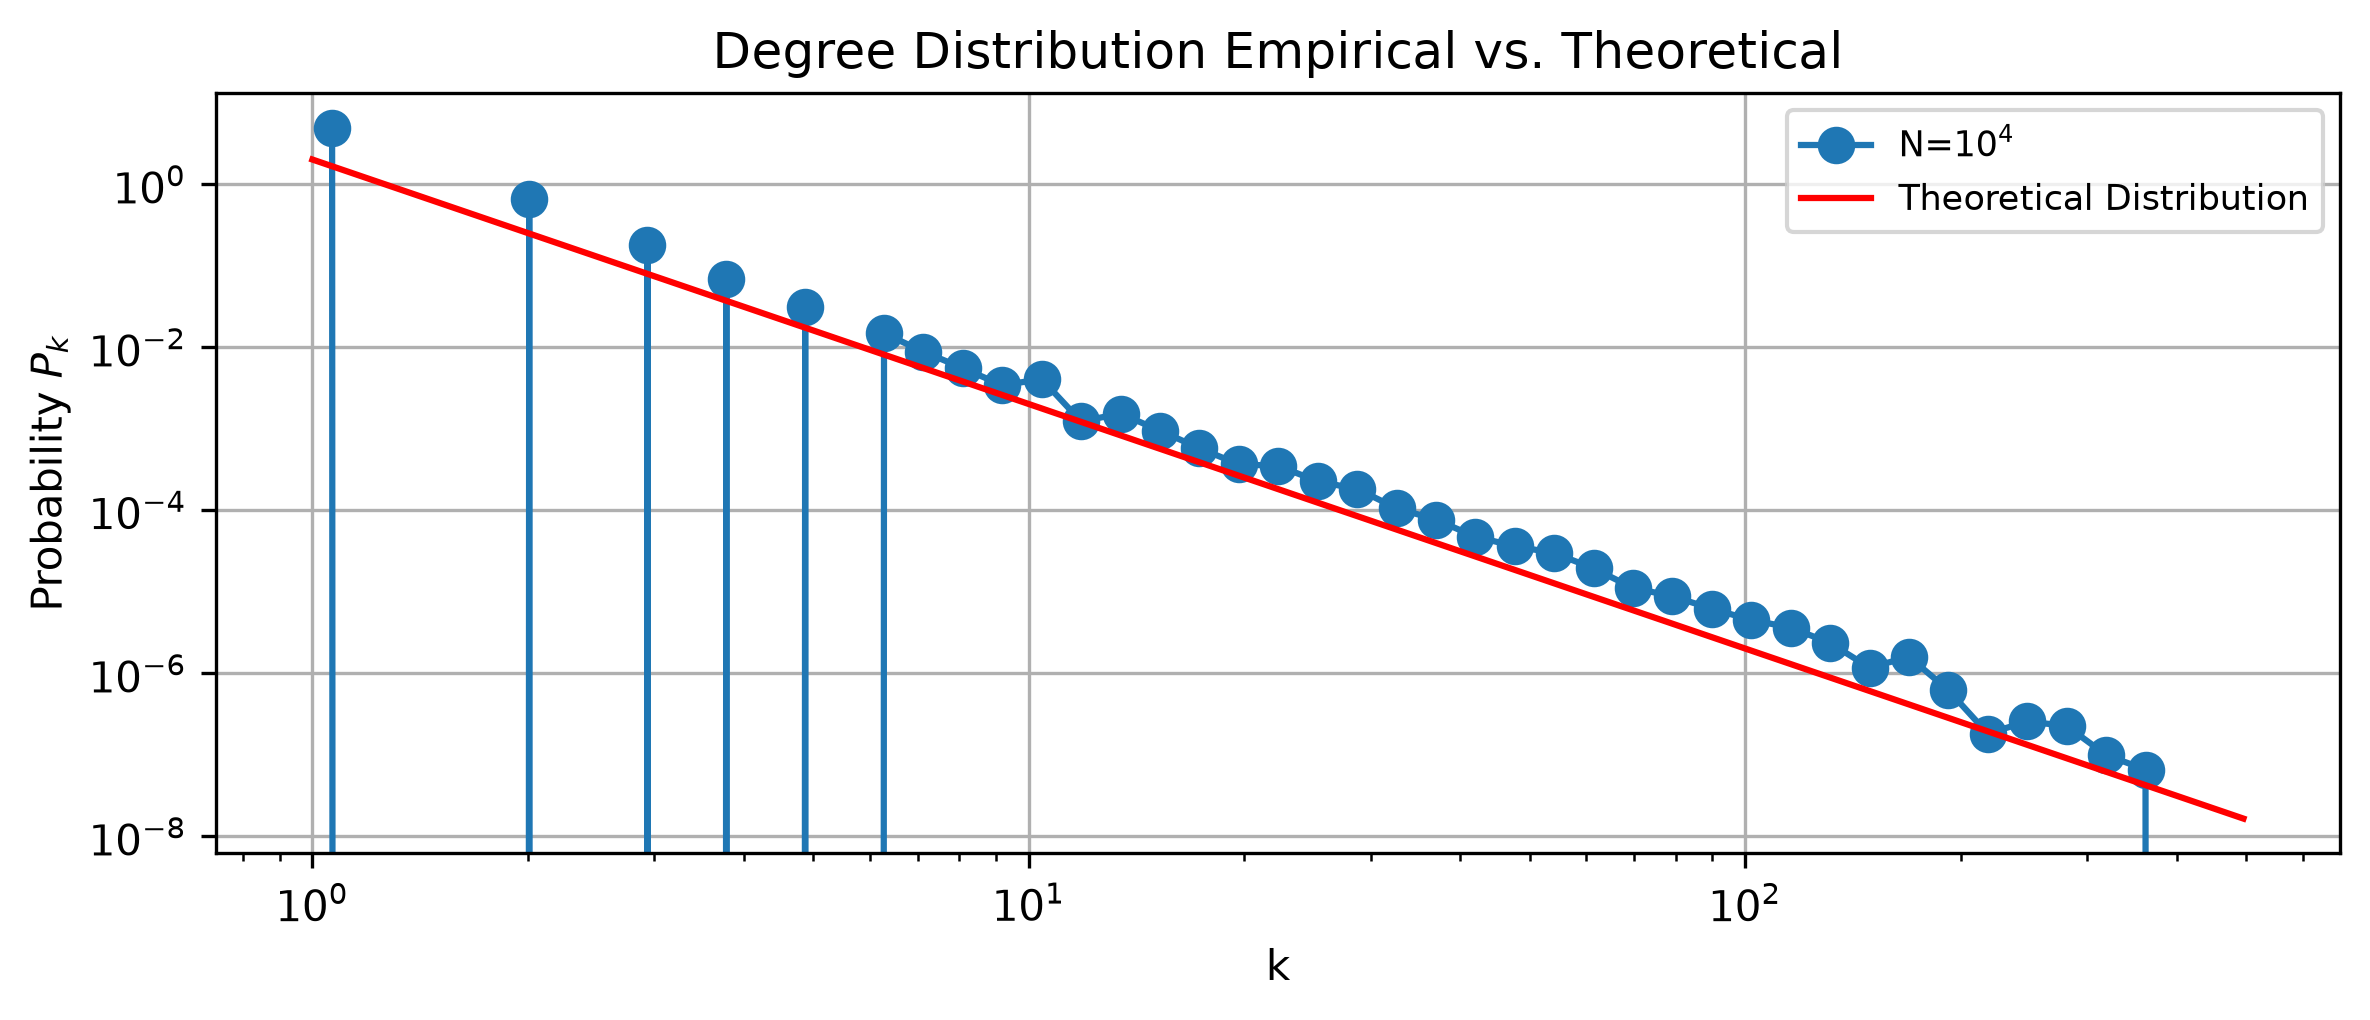

In [76]:
m=1
k=list(range(1,np.max(list(degs_10_4))))
print(degs)
theoretical = [2*(m**2)*(k_i**-3) for k_i in k]

#---Plotting the Degree Distribution 'k'
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=300,sharey=True,sharex=True)#Note: fig is the plot container, while ax (i.e., the 'axes') is the plot itself
bins = np.geomspace(1,np.max(list(degs_10_2)))

counts1, bin_edges = np.histogram(degs, bins=bins, density=True)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers, counts1, marker='o', ms = 8, label="N=$10^4$")

ax.loglog()
ax.plot(k,theoretical, color = 'r',ms = 2,label="Theoretical Distribution") #Plotting the Theoretical

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("Degree Distribution Empirical vs. Theoretical")
ax.set_xlabel("k")
ax.set_ylabel("Probability $P_k$")
ax.grid(True)

plt.tight_layout()
plt.show()

[[321, 160, 142, 217, 466, 173, 225, 139, 82, 247, 165, 218, 107, 94, 181, 52, 177, 68, 75, 172, 172, 47, 51, 162, 53, 136, 80, 62, 86, 71, 30, 129, 70, 79, 108, 116, 36, 90, 57, 36, 38, 81, 101, 58, 28, 23, 22, 47, 50, 48, 103, 38, 16, 35, 40, 46, 39, 29, 45, 87, 81, 29, 53, 65, 39, 23, 41, 22, 48, 64, 82, 10, 42, 47, 29, 88, 72, 47, 20, 37, 65, 33, 31, 53, 49, 72, 25, 51, 19, 71, 67, 38, 47, 95, 40, 40, 28, 36, 66, 49, 23, 72, 36, 34, 59, 20, 47, 35, 67, 93, 75, 36, 25, 53, 21, 13, 36, 33, 50, 44, 33, 20, 18, 35, 64, 30, 50, 19, 17, 32, 29, 18, 41, 35, 15, 18, 31, 26, 44, 58, 34, 59, 34, 17, 20, 29, 54, 34, 32, 58, 38, 11, 20, 20, 14, 59, 20, 34, 24, 39, 22, 41, 45, 60, 33, 29, 20, 42, 18, 15, 20, 21, 26, 39, 12, 33, 97, 31, 14, 6, 12, 22, 39, 21, 34, 27, 19, 20, 22, 33, 13, 17, 15, 16, 64, 29, 30, 34, 11, 22, 39, 9, 23, 25, 24, 18, 30, 16, 16, 14, 19, 35, 41, 19, 13, 39, 23, 21, 28, 23, 17, 17, 15, 29, 59, 42, 26, 10, 32, 27, 24, 11, 37, 17, 19, 26, 52, 20, 22, 46, 59, 12, 40, 18, 2

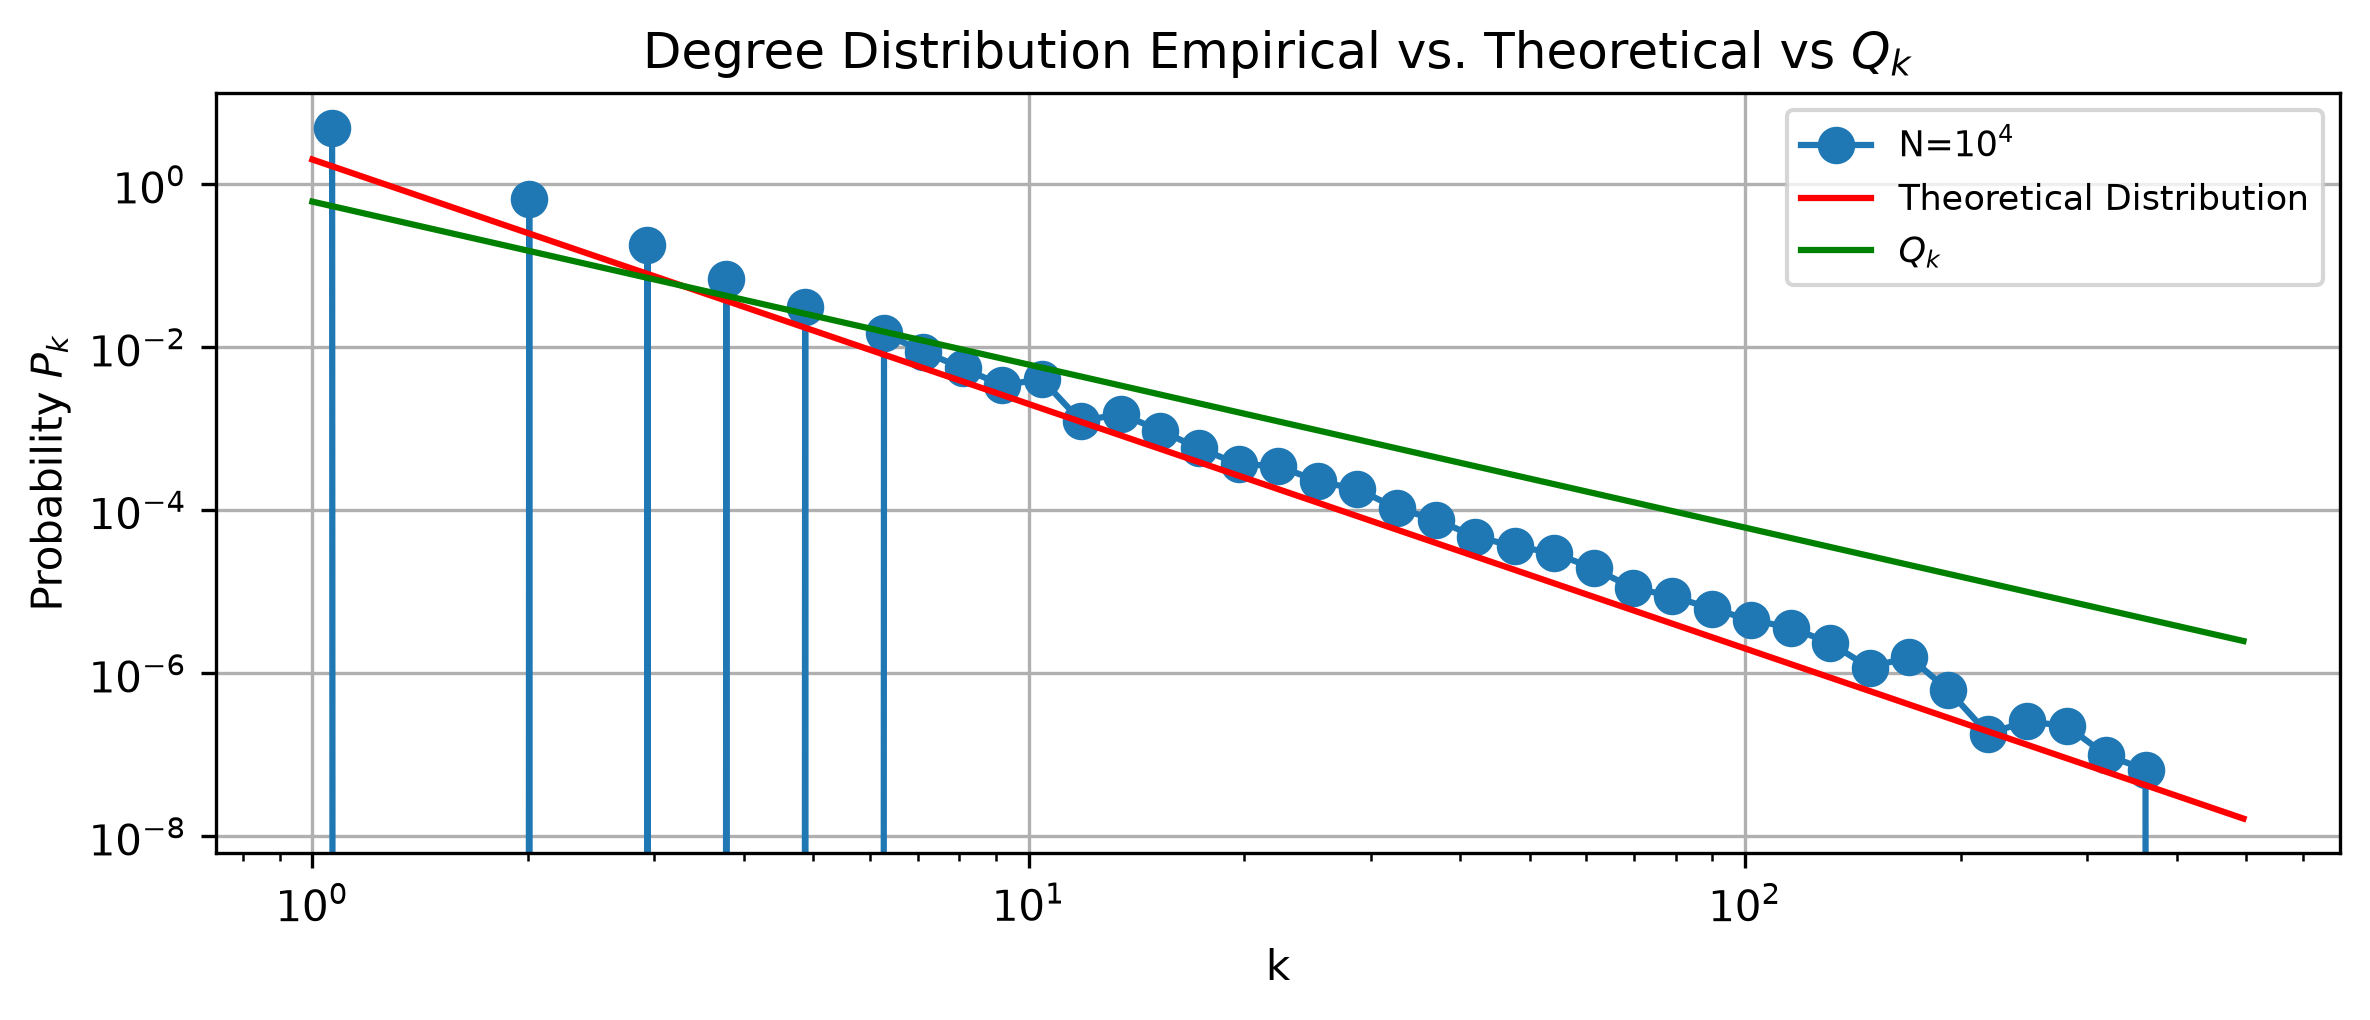

In [87]:
#(c)
m=1
k=list(range(1,np.max(list(degs_10_4))))
print(degs_10_2)
theoretical = [2*(m**2)*(k_i**-3) for k_i in k]
print(theoretical)
Q_k_top= [theoretical[k_i-1]*k_i for k_i in k]
print(Q_k_top)
Q_k = [Q_k/sum(Q_k_top) for Q_k in Q_k_top]

#---Plotting the Degree Distribution 'k'
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=300,sharey=True,sharex=True)#Note: fig is the plot container, while ax (i.e., the 'axes') is the plot itself
bins = np.geomspace(1,np.max(list(degs_10_2)))

counts1, bin_edges = np.histogram(degs, bins=bins, density=True)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers, counts1, marker='o', ms = 8, label="N=$10^4$")

ax.loglog()
ax.plot(k,theoretical, color = 'r',ms = 2,label="Theoretical Distribution") #Plotting the Theoretical
ax.plot(k,Q_k, color = 'g',ms = 2,label="$Q_k$") 

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("Degree Distribution Empirical vs. Theoretical vs $Q_k$")
ax.set_xlabel("k")
ax.set_ylabel("Probability $P_k$")
ax.grid(True)

plt.tight_layout()
plt.show()

#(d)

If Q_k is the expected probability of our edge attaching to any vertex with a degree k, then the average probability of our neighbor being is the degree distribution times this probability.

$$\sum_{k}{k}*Q(k) = \sum_{k}{k} * \frac{kP(k)}{\langle k \rangle} \rightarrow$$
$$= \sum_{k}{} * \frac{k^2P(k)}{\langle k \rangle}$$
$$= \frac{\langle k^2 \rangle}{\langle k \rangle}$$

If $\sum_k{k}P(k)=\langle k \rangle$, $\sum_k{k^2}P(k)=\langle k^2 \rangle$, and $P(k)=Ck^{-\gamma}$

Then:

$$\langle k \rangle = \sum_{k=k_{min}}^{k_{max}}{k}Ck^{-\gamma}$$
and,
$$\langle k^2 \rangle = \sum_{k=k_{min}}^{k_{max}}{k^2}Ck^{-\gamma}$$

which is equal to:

$$\langle k \rangle = C \sum_{k=k_{min}}^{k_{max}}{k^{-\gamma + 1}}$$
and,
$$\langle k^2 \rangle = C \sum_{k=k_{min}}^{k_{max}}{k^{-\gamma + 2}}$$

Since, $P(k)$ must equal 1 to reflect our probability, we define C as
$$C= \frac{1}{\sum_{k=k_{min}}^{k_{max}}k^{-\gamma}}$$

That gives us:

$$\langle k \rangle = \frac{\sum_{k=k_{min}}^{k_{max}}{k^{-\gamma + 1}}}{\sum_{k=k_{min}}^{k_{max}}k^{-\gamma}} $$
and,
$$\langle k^2 \rangle =  \frac{\sum_{k=k_{min}}^{k_{max}}{k^{-\gamma + 2}}}{\sum_{k=k_{min}}^{k_{max}}k^{-\gamma}} $$

for,
$$C= \frac{1}{\sum_{k=k_{min}}^{k_{max}}k^{-\gamma}}$$


In [42]:
N=10**4
gamma=2.3
k = range(1,1001)#kmin=1,kmax=1000

k_neigh= sum([k**(-gamma+2) for k in k])/sum([k**(-gamma) for k in k])
k_avg= sum([k**(-gamma+1) for k in k])/sum([k**(-gamma) for k in k])

print("k_neighbor: ", k_neigh)
print("k_average: ", k_avg)


k_neighbor:  124.97538508342737
k_average:  2.452222851581461


The friends of a randomly selected node have a higher mean degree than the nodes themselves because, hubs which have the highest degrees definitionally connect to more nodes than a normatitive node. This means, that as a normatitive node we are more likely to connect to a hub, since k_hub is simply greater than k_normatitive. In other words, we tend to connect to hubs simply because they have more opportunities for connections writ-large, and therfore our neighbors tend to be higher degree than ourselves. The alternative is some kind of flat-degree distribution where either everyone is a hub or no one.